In [127]:
import cv2
from cycler import cycler
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
import random
from scipy import stats
from skimage.metrics import (peak_signal_noise_ratio as psnr,
                             structural_similarity as ssim)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

from csc74030_zoi.paths import PROJECT_ROOT, PROCESSED, ROI_LABELS, get_roi
from csc74030_zoi.preprocessing import load_images
from csc74030_zoi.model import count_class


plt.rcParams["axes.prop_cycle"] = cycler(color=plt.cm.Set2.colors)
plt.rcParams["image.cmap"] = "plasma"

## Loading images

In [165]:
roi_df = pd.read_csv(ROI_LABELS)
roi_df["image"] = None
for i, row in roi_df.iterrows():
    image = get_roi(row, PROCESSED)
    roi_df.at[i, "image"] = image
    # if you need to save
    #plt.imsave(f"{PROJECT_ROOT}/data/rois/{row['roi']}.png", image, cmap="gray")
roi_df

,roi,label,antibiotic,diameter,y,x,image
0,4_37_1__denoised-y0-x0,resistant,am10,6,0,0,"[[17, 17, 17, 18, 18, 18, 18, 18, 18, 19, 19, ..."
1,4_37_1__denoised-y0-x1,susceptible,fep,27,0,256,"[[48, 46, 42, 35, 26, 18, 14, 14, 18, 26, 33, ..."
2,4_37_1__denoised-y0-x2,resistant,fox,14,0,512,"[[11, 16, 26, 29, 25, 21, 18, 17, 16, 16, 14, ..."
3,4_37_1__denoised-y0-x3,susceptible,mem,28,0,768,"[[25, 25, 25, 25, 25, 23, 19, 13, 10, 9, 10, 1..."
4,4_37_1__denoised-y1-x0,resistant,cpd,10,256,0,"[[55, 53, 51, 50, 51, 55, 59, 63, 67, 71, 74, ..."
...,...,...,...,...,...,...,...
3237,6_70_1__denoised-y2-x3,susceptible,cn,21,512,768,"[[104, 103, 103, 105, 108, 110, 109, 106, 101,..."
3238,6_70_1__denoised-y3-x0,susceptible,etp,27,768,0,"[[35, 36, 37, 37, 39, 40, 41, 42, 43, 45, 58, ..."
3239,6_70_1__denoised-y3-x1,susceptible,cip,33,768,256,"[[108, 109, 107, 104, 102, 103, 104, 106, 107,..."
3240,6_70_1__denoised-y3-x2,susceptible,pef,25,768,512,"[[102, 101, 102, 102, 102, 102, 102, 102, 102,..."


In [125]:
count_class(roi_df)

,count,percent
label,,
susceptible,1989,61.4
resistant,1115,34.4
intermediate,84,2.6
not read,54,1.7


Note: The `not read` label may not be helpful as it seems this occurred when the machine had difficulty reading the disk or determining the zone of inhibition boundary, so we'll drop it.

In [166]:
mask = roi_df["label"] != "not read"
roi_df = roi_df[mask]
count_class(roi_df)

,count,percent
label,,
susceptible,1989,62.4
resistant,1115,35.0
intermediate,84,2.6


## 1. Image Database (5)
Construct an image database containing multiple object classes. The dataset should include both high-quality images and images degraded by noise, blur, illumination changes, or compression artifacts to simulate real-world conditions (see Midterm Project).

### Class Examples
We'll plot example images of each class.

In [167]:
labels = roi_df["label"].unique()
examples = []
for label in labels:
    mask = roi_df["label"] == label
    example = roi_df[mask].iloc[7]
    examples.append({"roi": example["roi"], "image": example["image"], "label": example["label"]})

examples_df = pd.DataFrame(examples)
examples_df

,roi,image,label
0,5_10_1__denoised-y0-x1,"[[54, 53, 51, 49, 48, 47, 46, 45, 45, 63, 75, ...",resistant
1,4_37_1__denoised-y3-x1,"[[125, 118, 113, 115, 116, 114, 114, 118, 121,...",susceptible
2,7_12_1__denoised-y2-x2,"[[146, 146, 146, 146, 146, 145, 144, 142, 141,...",intermediate


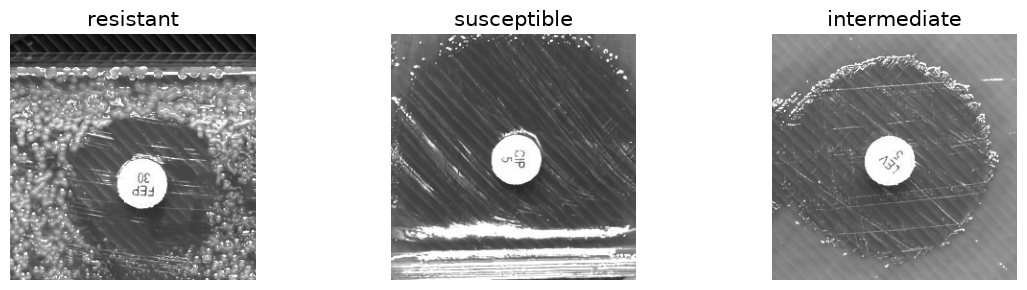

In [168]:
# n = len(examples)
# figsize=(3*n, 3)

fig, axes = plt.subplots(1, 3, sharey=True, figsize=(3*4, 3))
for i, row in examples_df.iterrows():
    axes[i].set_title(row.label, fontsize=15)
    axes[i].imshow(row.image, cmap="gray", vmin=0, vmax=255)
    axes[i].axis("off")
plt.tight_layout()

In [169]:
half = roi_df.shape[0] // 2

We will modify half of the images.

In [ ]:
#for i, row in roi_df.iterrows():
    

## 2. Image filtering and enhancement (10)

Apply image restoration and enhancement techniques to improve image quality before analysis. Methods may include median filtering, Gaussian filtering, deblurring, contrast enhancement, gamma correction, and histogram equalization. The goal is to reduce noise while preserving important object details.

Our images have may signals interfering with disk and zone boundaries. We will use the `zone` example to evaluate potential noise. We can also explore sharpening zone boundaries as in the `disk` example as an additional opportunity for enhancement.

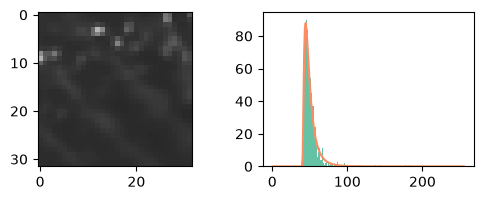

In [108]:
patch = examples_df.loc[1]["image"][50:82, 50:82]
fig, axes = plt.subplots(1, 2, figsize=(3*2, 2))
shape, loc, scale = stats.lognorm.fit(patch.ravel())
axes[0].imshow(patch, cmap="gray", vmin=0, vmax=255)
counts, bin_edges, _ = axes[1].hist(patch.ravel(), bins=256, range=(0, 256))

# With modification suggested by Claude Sonnet 5.5 to show lognormal curve
centers = (bin_edges[:-1] + bin_edges[1:]) / 2
axes[1].plot(centers, stats.lognorm.pdf(centers, shape, loc, scale) * patch.size * (bin_edges[1] - bin_edges[0]))

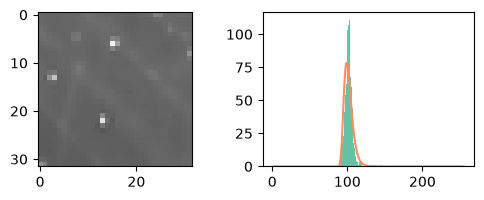

In [114]:
patch = examples_df.loc[4]["image"][90:122, 20:52]
fig, axes = plt.subplots(1, 2, figsize=(3*2, 2))
shape, loc, scale = stats.lognorm.fit(patch.ravel())
axes[0].imshow(patch, cmap="gray", vmin=0, vmax=255)
counts, bin_edges, _ = axes[1].hist(patch.ravel(), bins=256, range=(0, 256))

# With modification suggested by Claude Sonnet 5.5 to show lognormal curve
centers = (bin_edges[:-1] + bin_edges[1:]) / 2
axes[1].plot(centers, stats.lognorm.pdf(centers, shape, loc, scale) * patch.size * (bin_edges[1] - bin_edges[0]))

## With Haralick, box counting, chain code, areas, LBP

In [94]:
FUNCS = [haralick_features, box_count_features, chain_code_features, 
         areas_features, lbp_features]

groups = roi_group(roi_df)
train_X, y = prepare_features_for_images(roi_df, verbose=False)
svm = train_features(train_X, y, verbose=False)
cv = GroupKFold(n_splits=4)
all_features_pred = cross_val_predict(svm, train_X, y, cv=cv, groups=groups)
print(classification_report(y, all_features_pred, zero_division=0))
print(confusion_matrix(y, all_features_pred, labels=["resistant", "susceptible"]))

              precision    recall  f1-score   support

   resistant       0.83      0.71      0.77        84
 susceptible       0.79      0.88      0.83       100

    accuracy                           0.80       184
   macro avg       0.81      0.80      0.80       184
weighted avg       0.81      0.80      0.80       184

[[60 24]
 [12 88]]
